# Visualising ECG signals
`ECGDrawing` takes a called-and-extracted reader instance and renders the
lead-specific ECG signals on a GridSpec figure with clinical ECG paper scaling.

The layout is fully controlled by a `mapper` dict that maps each lead name to
a `(row_index, col_slice)` position in the GridSpec. 
The ECG visualisation is primarily controlled using 
`ECGStyle` and overwritten using various kwarg parameters.

In [1]:
from tempfile import NamedTemporaryFile

import matplotlib.pyplot as plt
from ecgprocess.example_data.examples import config_file, list_dicom_paths
from ecgprocess.plot_ecgs import ECGDrawing, ECGStyle
from ecgprocess.process_dicom import ECGDICOMReader
from ecgprocess.utils.config_tools import ConfigParser, DataMap

CM_TO_IN: float = 1 / 2.54

dicom_path = list_dicom_paths()["example_dicom_2"]

## Canonical ECG image

The standard clinical ECG is printed on a grid of 1 mm small squares and 5 mm
large squares. 
`ECGDrawing` cam replicate this using `matplotlib.gridspec.GridSpec`, one panel per lead, with minor and major grid lines set based on `ECGStyle`'s
`paper_speed` (mm/s) and `mm_per_mv` (mm/mV) fields. 
Signal traces are allowed to cross panel borders (`clip_on_trace=False`) replicating the physical paper look for large deflections.

The caller controls which leads appear and where via a `mapper` dict:
```python
mapper = {
    # row 0, column 0
    'I':  (0, slice(0, 1)),  
    # row 0, column 1
    'II': (0, slice(1, 2)), 
    ...
}
```

Steps:
1. Parse a config that maps lead names to DICOM tag paths.
2. Call the reader, then `.extract()` to populate `WaveForms` and `MetaData`.
3. Build a `mapper` from the leads that have data.
4. Pass everything to `ECGDrawing`.

### Step 1: Parse configuration

A config dict maps each lead name to its DICOM tag path. `ConfigParser` turns it into a structured config object and `DataMap` binds it to the expected attribute names.

In [2]:
# Config maps standard 12-lead order for this ECG DICOM format.
# skip_empty=True silently drops leads whose tag paths are absent in the file.
ecg_config = {
    "WaveForms": [
        "I					WaveformData.ECG_Leads_0",
        "II					WaveformData.ECG_Leads_1",
        "III					WaveformData.ECG_Leads_2",
        "aVR					WaveformData.ECG_Leads_3",
        "aVL					WaveformData.ECG_Leads_4",
        "aVF					WaveformData.ECG_Leads_5",
        "V1					WaveformData.ECG_Leads_6",
        "V2					WaveformData.ECG_Leads_7",
        "V3					WaveformData.ECG_Leads_8",
        "V4					WaveformData.ECG_Leads_9",
        "V5					WaveformData.ECG_Leads_10",
        "V6					WaveformData.ECG_Leads_11",
    ],
    "MedianBeats": [
        "I					WaveformData.Median_Beats_0",
        "II					WaveformData.Median_Beats_1",
        "III					WaveformData.Median_Beats_2",
        "aVR					WaveformData.Median_Beats_3",
        "aVL					WaveformData.Median_Beats_4",
        "aVF					WaveformData.Median_Beats_5",
        "V1					WaveformData.Median_Beats_6",
        "V2					WaveformData.Median_Beats_7",
        "V3					WaveformData.Median_Beats_8",
        "V4					WaveformData.Median_Beats_9",
        "V5					WaveformData.Median_Beats_10",
        "V6					WaveformData.Median_Beats_11",
    ],
    "MetaData": [
        "number of leads				Waveform Sequence_0.Number of Waveform Channels",
        "sampling frequency (original)			Waveform Sequence_0.Sampling Frequency",
        "signal_unit					Waveform Sequence_0.Channel Definition Sequence_0.Channel Sensitivity Units Sequence_0.Code Meaning",
    ],
}
# NOTE using a temp file here to mimic reading the file.
# during actual applications the config information will live in
# a file which can be used for multiple ECG processing calls.
with NamedTemporaryFile("w") as tmp:
    config_file(path=tmp.name, text=ecg_config)
    cfg = ConfigParser(tmp.name)()
cfg.map(mapper=DataMap())
print(cfg)

ConfigParser
[WaveForms]
	I                                WaveformData.ECG_Leads_0
	II                               WaveformData.ECG_Leads_1
	III                              WaveformData.ECG_Leads_2
	aVR                              WaveformData.ECG_Leads_3
	aVL                              WaveformData.ECG_Leads_4
	aVF                              WaveformData.ECG_Leads_5
	V1                               WaveformData.ECG_Leads_6
	V2                               WaveformData.ECG_Leads_7
	V3                               WaveformData.ECG_Leads_8
	V4                               WaveformData.ECG_Leads_9
	V5                               WaveformData.ECG_Leads_10
	V6                               WaveformData.ECG_Leads_11

[MedianBeats]
	I                                WaveformData.Median_Beats_0
	II                               WaveformData.Median_Beats_1
	III                              WaveformData.Median_Beats_2
	aVR                              WaveformData.Median_Beats_3
	a

### Step 2: Read signals

`ECGDICOMReader` extracts raw waveforms and resamples to 500 Hz. Note, the DICOM signals are in μV so we will need to either change the plotting y-axis defaults or multiply the signal by 1,000. Here we are changing the y-axis settings. 

In [3]:
reader = ECGDICOMReader(resample_500=True)
reader(path=dicom_path)
reader.extract(config=cfg)
print(f"signal unit: {reader.MetaData['signal_unit']}")

signal unit: microvolt


### Step 3: Build the lead-layout mapper

A `mapper` dict assigns each lead name to a `(row, col_slice)` position in the GridSpec. This can be used to merge multiple pannels into a single plotting area - see below for an ECG illustration including a rhythm strip. 

In [4]:
# #### build 4-column clinical mapper
mapper = {
    "I": (0, slice(0, 1)),
    "aVR": (0, slice(1, 2)),
    "V1": (0, slice(2, 3)),
    "V4": (0, slice(3, 4)),
    "II": (1, slice(0, 1)),
    "aVL": (1, slice(1, 2)),
    "V2": (1, slice(2, 3)),
    "V5": (1, slice(3, 4)),
    "III": (2, slice(0, 1)),
    "aVF": (2, slice(1, 2)),
    "V3": (2, slice(2, 3)),
    "V6": (2, slice(3, 4)),
}
mapper

{'I': (0, slice(0, 1, None)),
 'aVR': (0, slice(1, 2, None)),
 'V1': (0, slice(2, 3, None)),
 'V4': (0, slice(3, 4, None)),
 'II': (1, slice(0, 1, None)),
 'aVL': (1, slice(1, 2, None)),
 'V2': (1, slice(2, 3, None)),
 'V5': (1, slice(3, 4, None)),
 'III': (2, slice(0, 1, None)),
 'aVF': (2, slice(1, 2, None)),
 'V3': (2, slice(2, 3, None)),
 'V6': (2, slice(3, 4, None))}

### Step 4: Render

`ECGDrawing` renders all leads onto a `GridSpec` figure with clinical ECG-paper grid lines (1 mm and 5 mm squares). The speed/gain annotation is added to the figure afterwards.

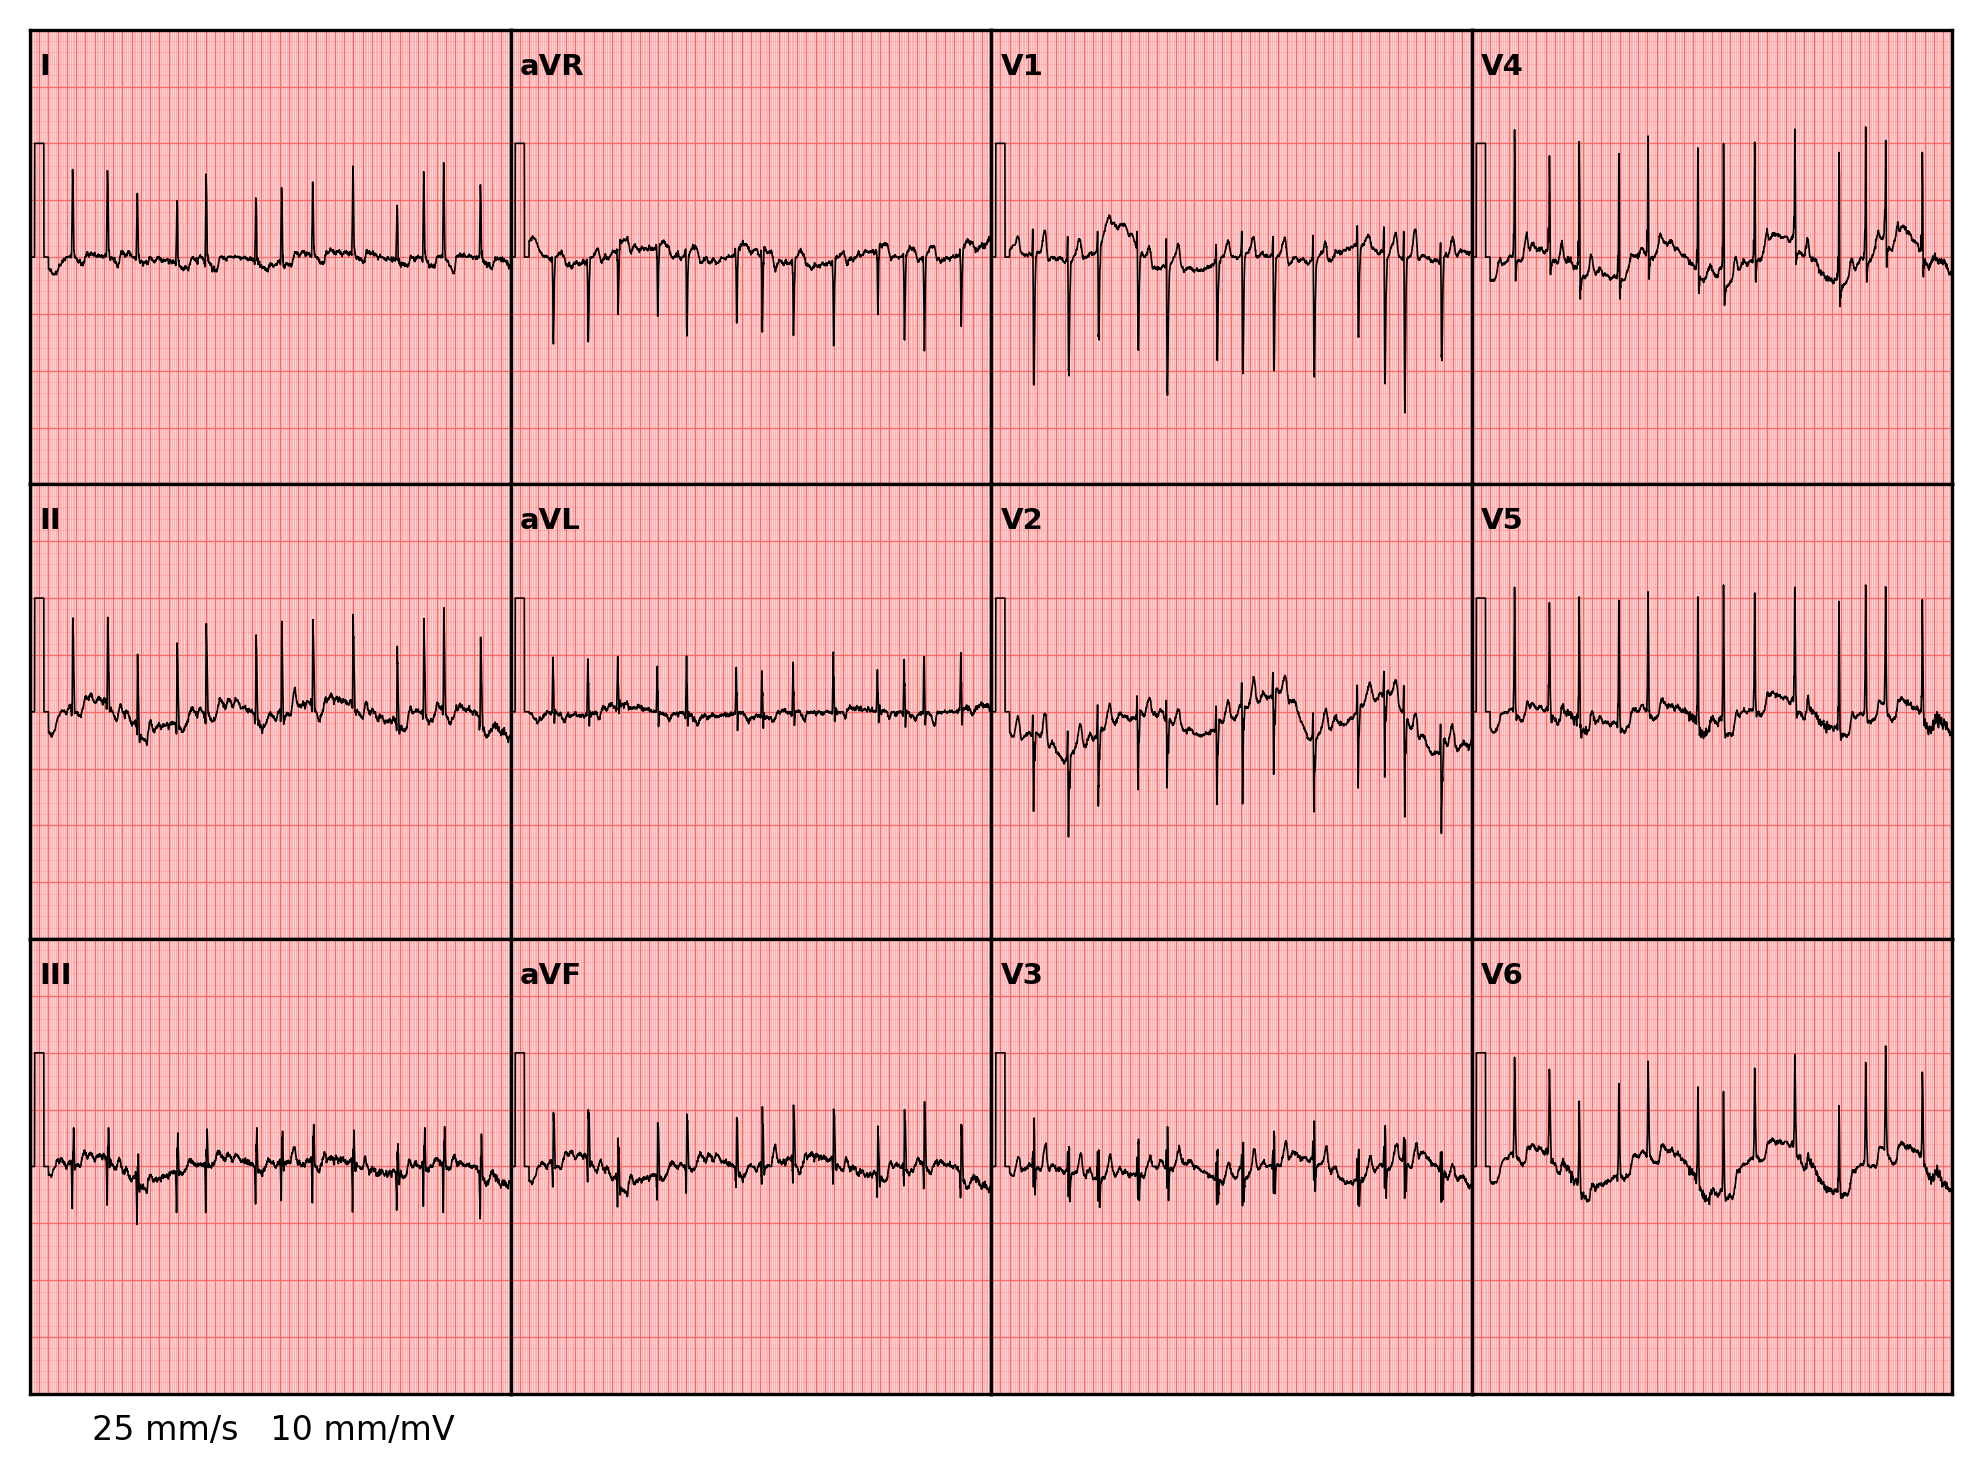

In [5]:
# Determine sampling_rate from MetaData; fall back to 500 if unavailable
samplefreq = reader.MetaData.get("sampling frequency (processed)") or 500
# set the limit to  μV and update the mm_per_mv
ylim = (-2000, 2000)
mm_mv = 10 / 1000
# set the style
style = ECGStyle(
    figsize=(21 * CM_TO_IN, 15 * CM_TO_IN),
    dpi=300,
    y_lim=ylim,
    mm_per_mv=mm_mv,
)
drawing = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    cal_pulse="square",
)
fig = drawing.figure
# #### speed / gain annotation
# NOTE still saying 10 mm/mV and not 0.1 mm/μV because the
# y_lim and mv_mm (gain) have been scaled to this constant
# This is equivalent to mapping the signal to mV (division by 1000)
fig.text(
    0.15,
    0.08,
    f"25 mm/s   10 mm/mV",
    fontsize=8,
    va="bottom",
    ha="left",
    transform=fig.transFigure,
)
plt.show()

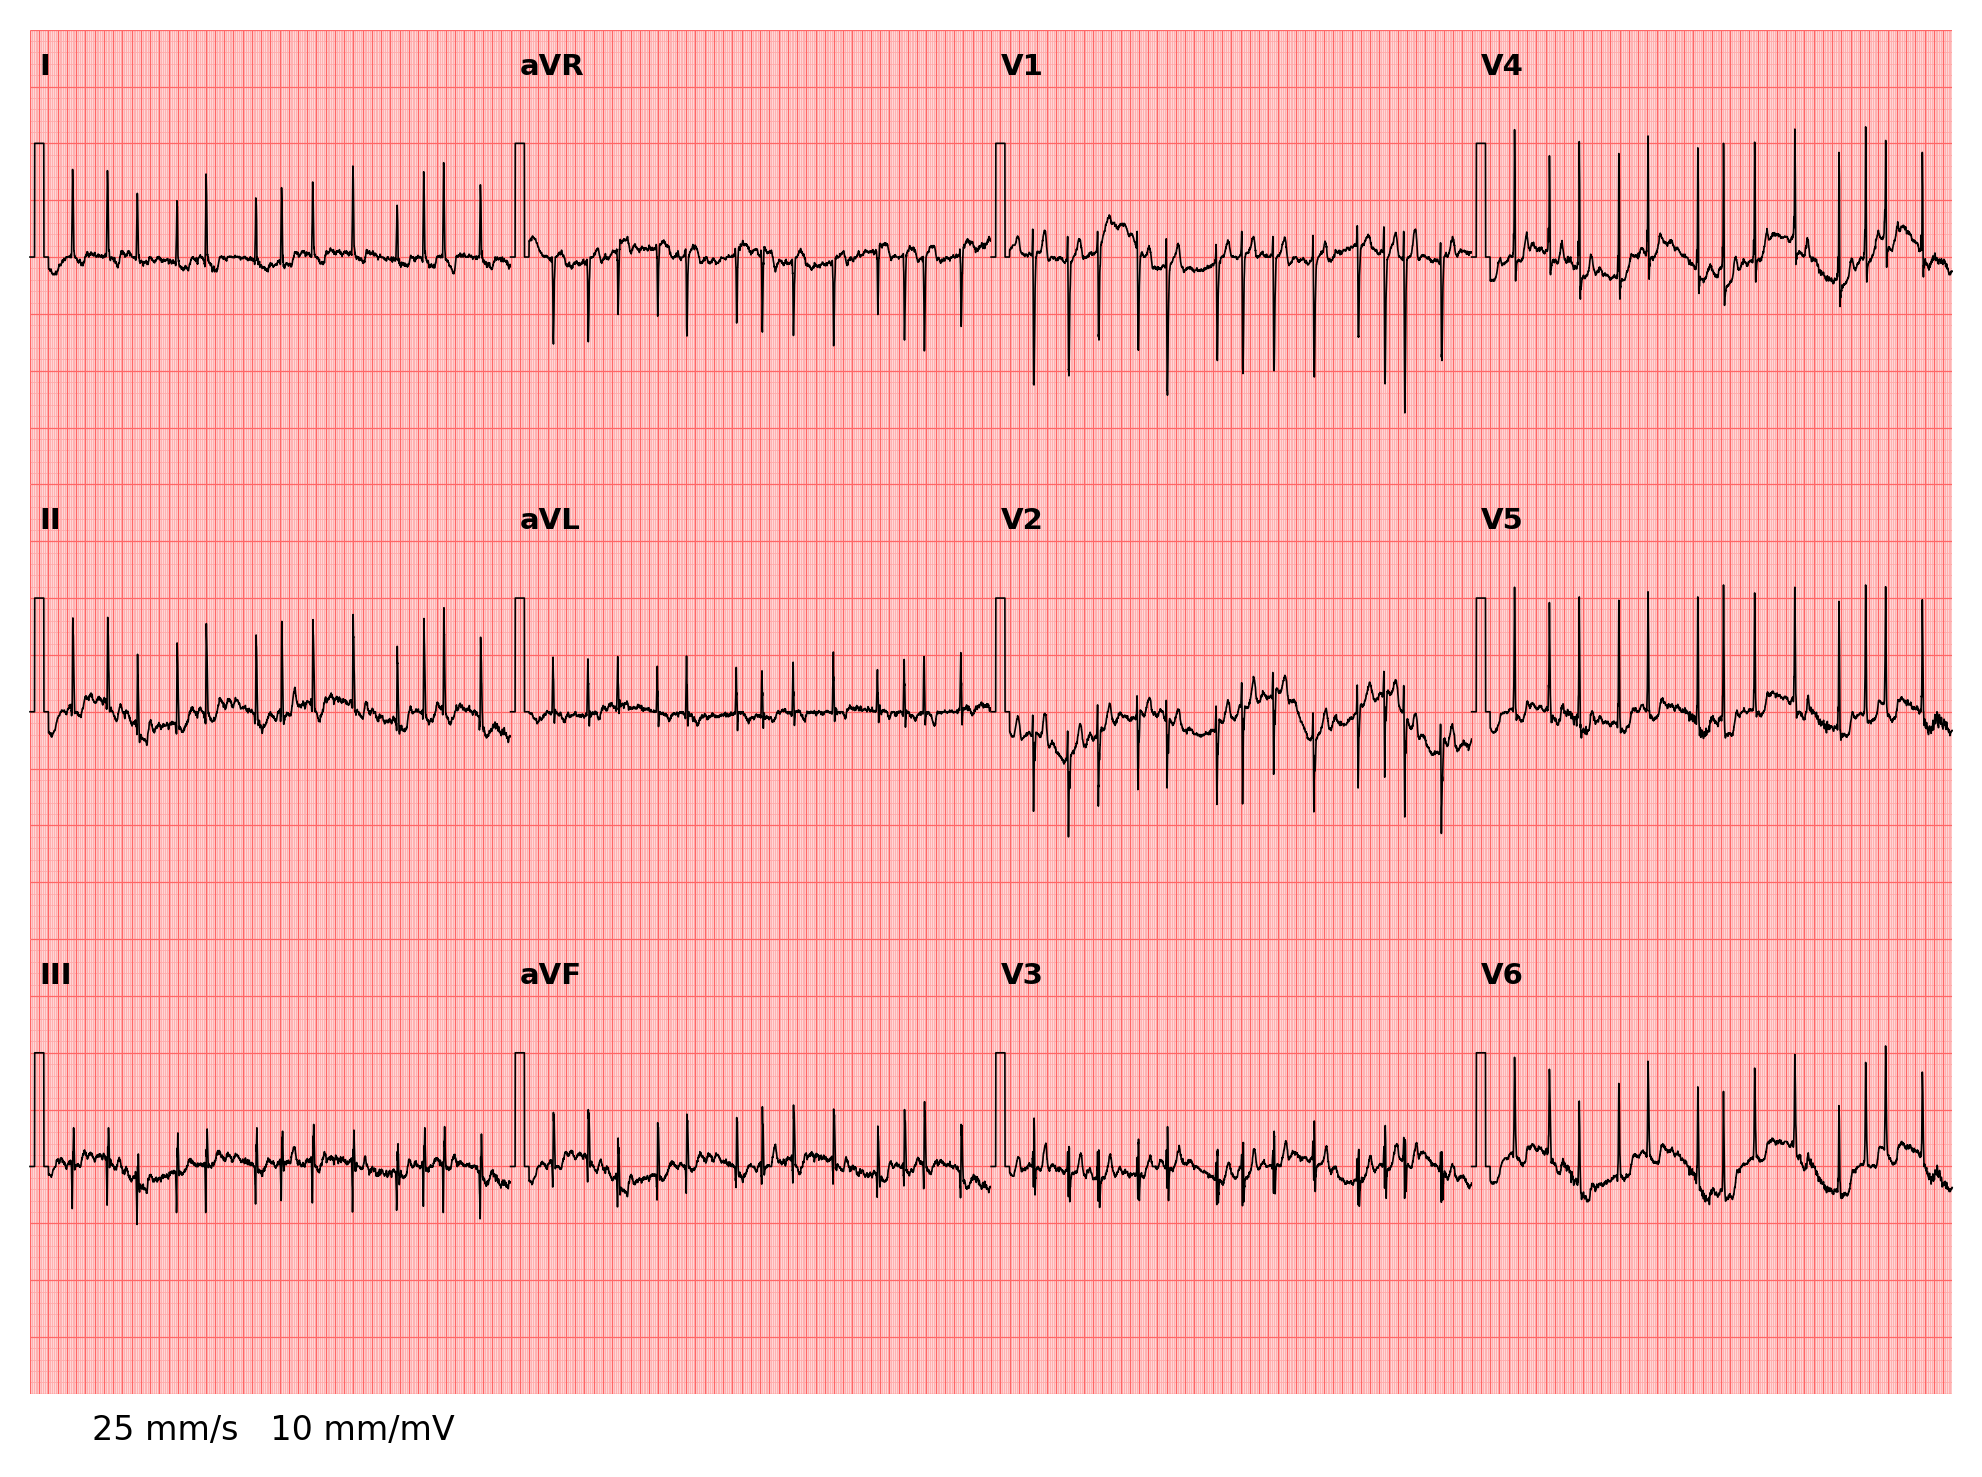

In [6]:
# #### canonical ECG without panel borders (clinical paper look)
# Same parameters as the cell above; spine removal added.
drawing_ns = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    cal_pulse="square",
)
fig_ns = drawing_ns.figure
fig_ns.text(
    0.15,
    0.08,
    f"25 mm/s   10 mm/mV",
    fontsize=8,
    va="bottom",
    ha="left",
    transform=fig_ns.transFigure,
)
for ax in drawing_ns.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Non-traditional layout: 3-lead monitoring strip

The `mapper` dict controls which leads appear and where. Passing only three
leads, I, II, III stacked in a single column, produces a compact monitoring
strip common in bedside telemetry displays.

Lead 'V1' is in signal data but not requested in mapper.
Lead 'V2' is in signal data but not requested in mapper.
Lead 'V3' is in signal data but not requested in mapper.
Lead 'V4' is in signal data but not requested in mapper.
Lead 'V5' is in signal data but not requested in mapper.
Lead 'V6' is in signal data but not requested in mapper.
Lead 'aVF' is in signal data but not requested in mapper.
Lead 'aVL' is in signal data but not requested in mapper.
Lead 'aVR' is in signal data but not requested in mapper.


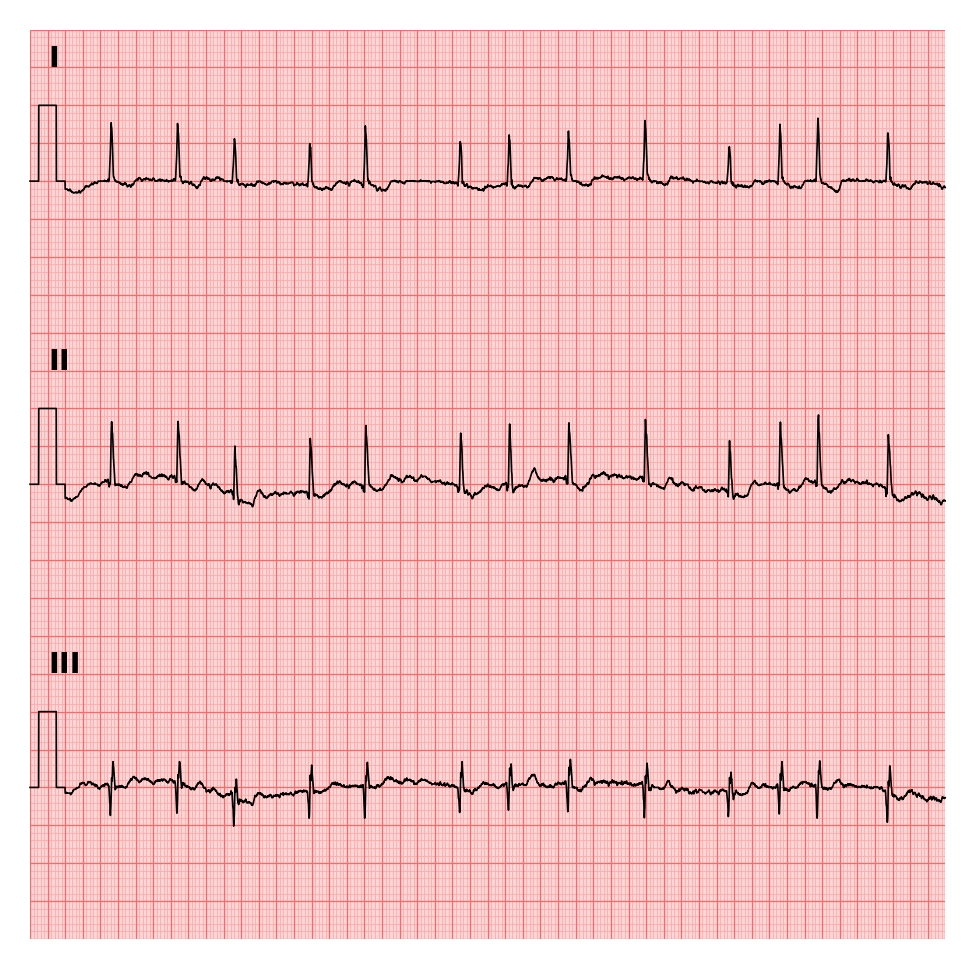

In [7]:
# #### 3-lead monitoring layout
mapper_3lead = {
    "I": (0, slice(0, 1)),
    "II": (1, slice(0, 1)),
    "III": (2, slice(0, 1)),
}
style_3lead = ECGStyle(
    figsize=(10 * CM_TO_IN, 10 * CM_TO_IN),
    dpi=300,
    y_lim=ylim,
    mm_per_mv=mm_mv,
)
drawing_3lead = ECGDrawing()(
    reader,
    mapper=mapper_3lead,
    style=style_3lead,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    cal_pulse="square",
)
for ax in drawing_3lead.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Per-lead trace styling

Any `kwargs_*` parameter accepts either a flat dict (uniform across all leads)
or a dict-of-dicts (one entry per lead). Passing a dict-of-dicts lets you
style each lead independently.

Here the same 3-lead layout is redrawn with a different trace colour per lead.

Lead 'V1' is in signal data but not requested in mapper.
Lead 'V2' is in signal data but not requested in mapper.
Lead 'V3' is in signal data but not requested in mapper.
Lead 'V4' is in signal data but not requested in mapper.
Lead 'V5' is in signal data but not requested in mapper.
Lead 'V6' is in signal data but not requested in mapper.
Lead 'aVF' is in signal data but not requested in mapper.
Lead 'aVL' is in signal data but not requested in mapper.
Lead 'aVR' is in signal data but not requested in mapper.


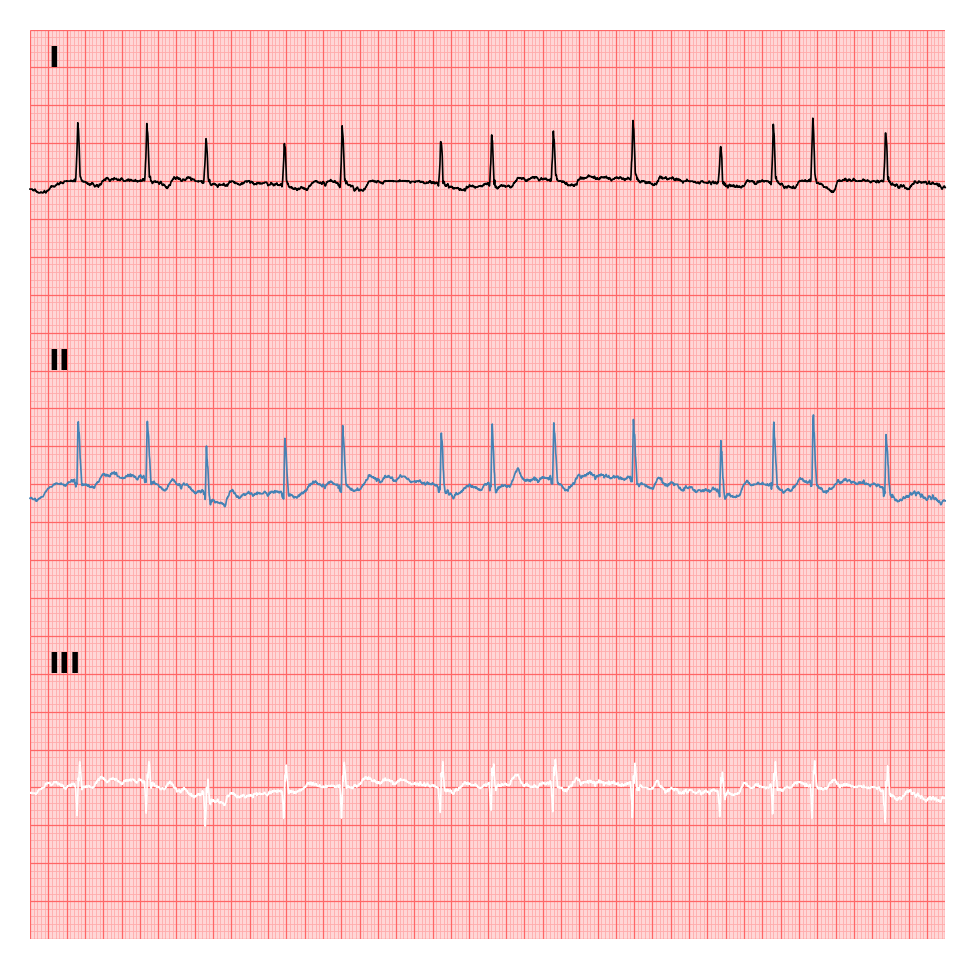

In [8]:
# #### per-lead trace colour: I=black, II=steelblue, III=white
drawing_3lead_kw = ECGDrawing()(
    reader,
    mapper=mapper_3lead,
    style=style_3lead,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    kwargs_plot={
        "I": {"color": "black"},
        "II": {"color": "steelblue"},
        "III": {"color": "white"},
    },
)
for ax in drawing_3lead_kw.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Continuous ECG paper layout

On physical ECG paper a 10-second recording prints as a single continuous
strip. The 4-column `mapper` layout already places leads side-by-side; this
cell tiles the x-axis to match: each column displays 1/4 of the total signal
duration, and the x values continue from the previous column's end —
mimicking the paper tape. Each row resets to zero independently so that leads
in the same column always show the same time window.

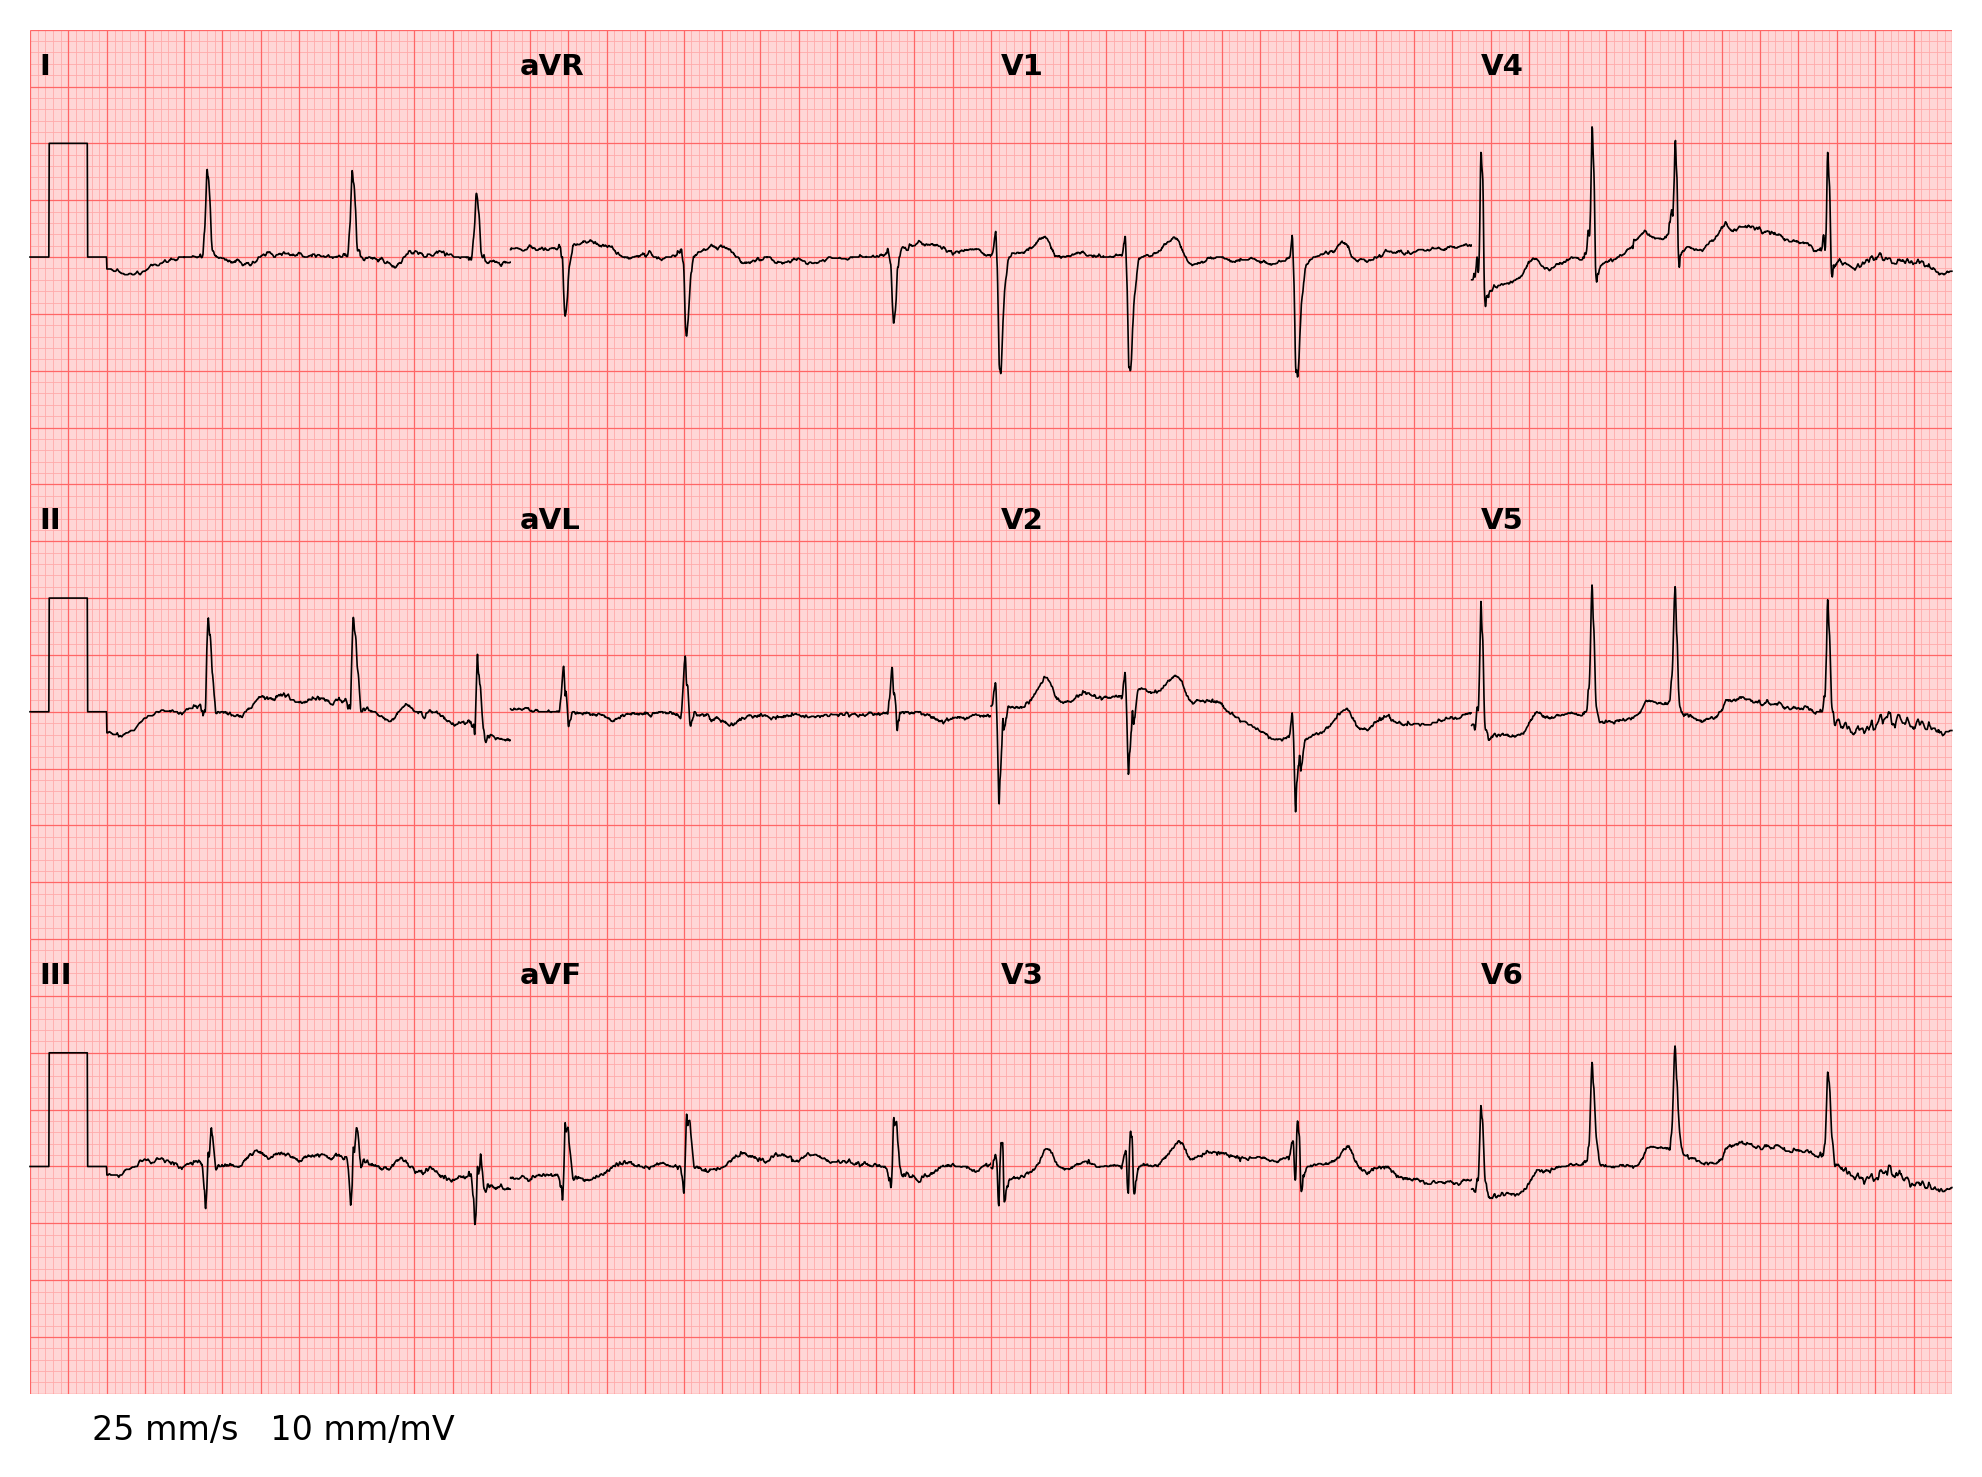

In [9]:
# #### continuous ECG paper layout
drawing_cont = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    cal_pulse="square",
    cal_leads=['I', 'II', 'III', 'II strip'],
).tile_x_axis()
fig_cont = drawing_cont.figure
fig_cont.text(
    0.15,
    0.08,
    "25 mm/s   10 mm/mV",
    fontsize=8,
    va="bottom",
    ha="left",
    transform=fig_cont.transFigure,
)
for ax in drawing_cont.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Combined 12-lead with Lead II rhythm strip

A standard clinical printout shows the 12-lead grid followed immediately by a
full-width Lead II rhythm strip. Because `reader.WaveForms` is a plain dict, a
temporary key `'II_strip'` can be added to map Lead II to a second position
(row 3, spanning all 4 columns). The key is removed after drawing.

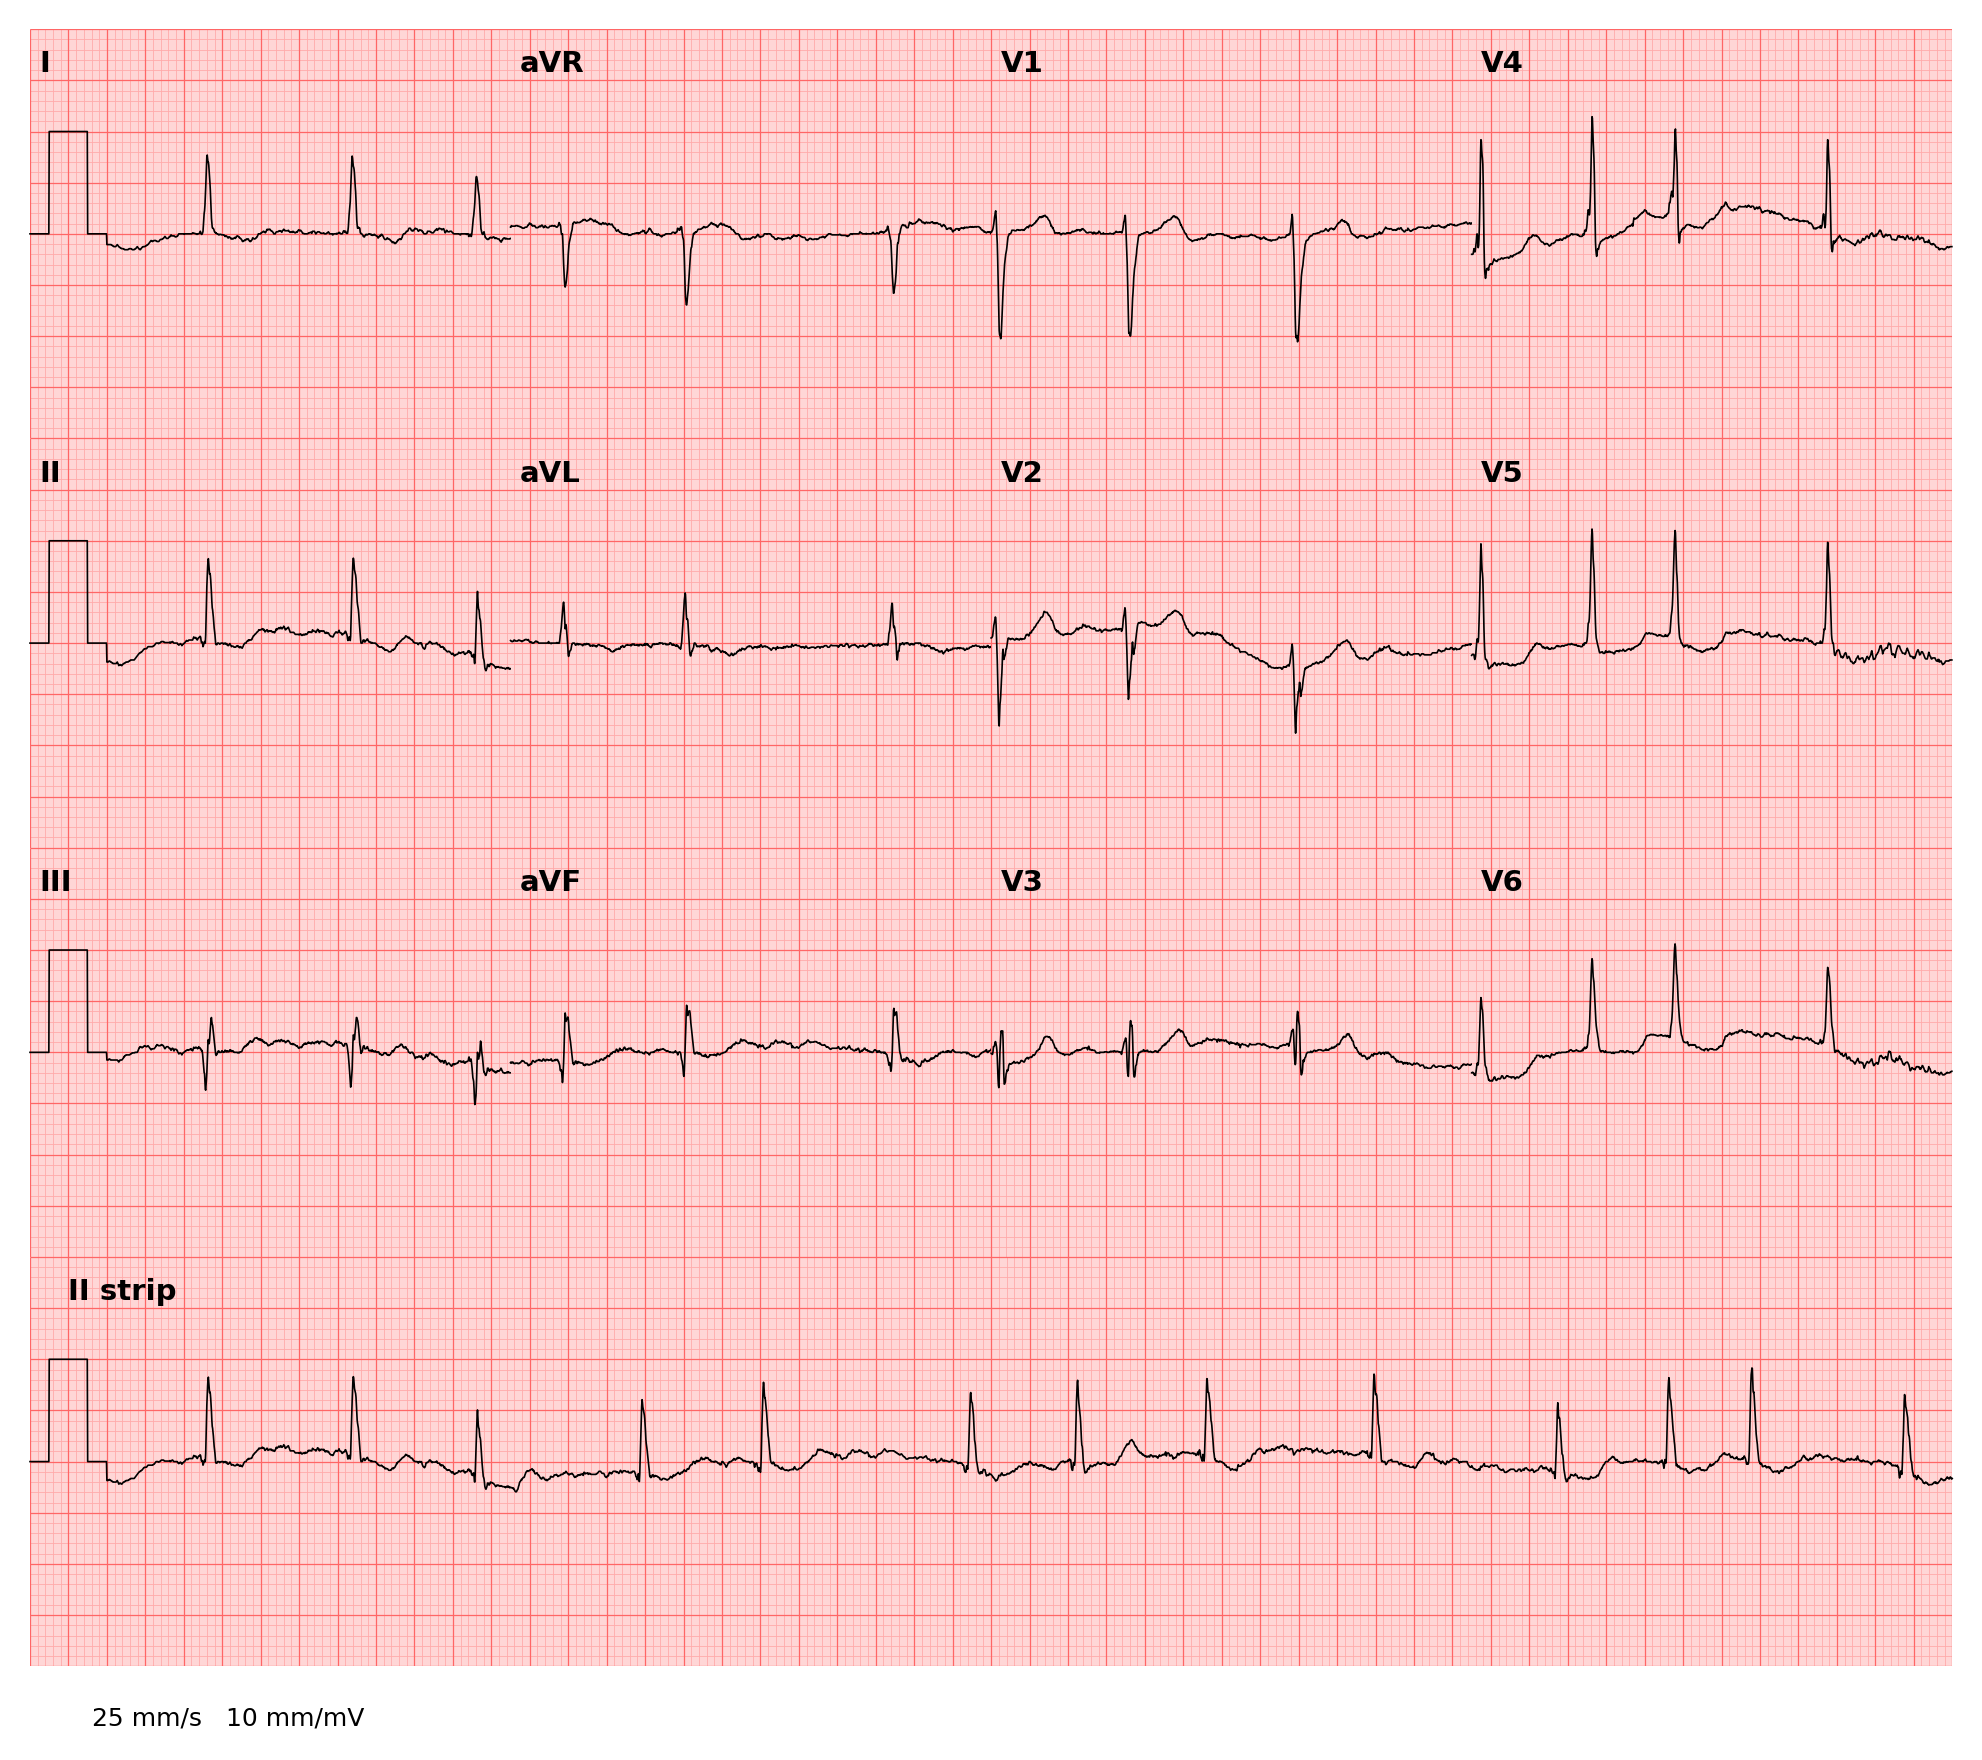

In [10]:
# #### extend mapper with a full-width Lead II rhythm strip at row 3
reader.WaveForms["II strip"] = reader.WaveForms["II"]
mapper_rhythm = dict(mapper)
# combining four panels using slice
mapper_rhythm["II strip"] = (3, slice(0, 4))
style_rhythm = ECGStyle(
    figsize=(21 * CM_TO_IN, 18 * CM_TO_IN),
    dpi=300,
    y_lim=ylim,
    mm_per_mv=mm_mv,
)
drawing_rhythm = ECGDrawing()(
    reader,
    mapper=mapper_rhythm,
    style=style_rhythm,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    cal_pulse="square",
    cal_leads=['I', 'II', 'III', 'II strip'],
).tile_x_axis()
fig_r = drawing_rhythm.figure
fig_r.text(
    0.15,
    0.08,
    f"25 mm/s   10 mm/mV",
    fontsize=6,
    va="bottom",
    ha="left",
    transform=fig_r.transFigure,
)
# #### remove inter-panel borders
for ax in drawing_rhythm.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()
# #### clean up temporary key
del reader.WaveForms["II strip"]

## Overplotting: clip_on_trace

`ECGStyle.clip_on_trace` controls whether signal traces are clipped at panel
boundaries. The default (`False`) allows large deflections (e.g. tall R-waves
or deep aVL Q-waves) to cross into adjacent panels, replicating the look of
physical ECG paper. Setting `clip_on_trace=True` clips traces to each panel.

The demo scales aVL ×5 to make the difference visible.

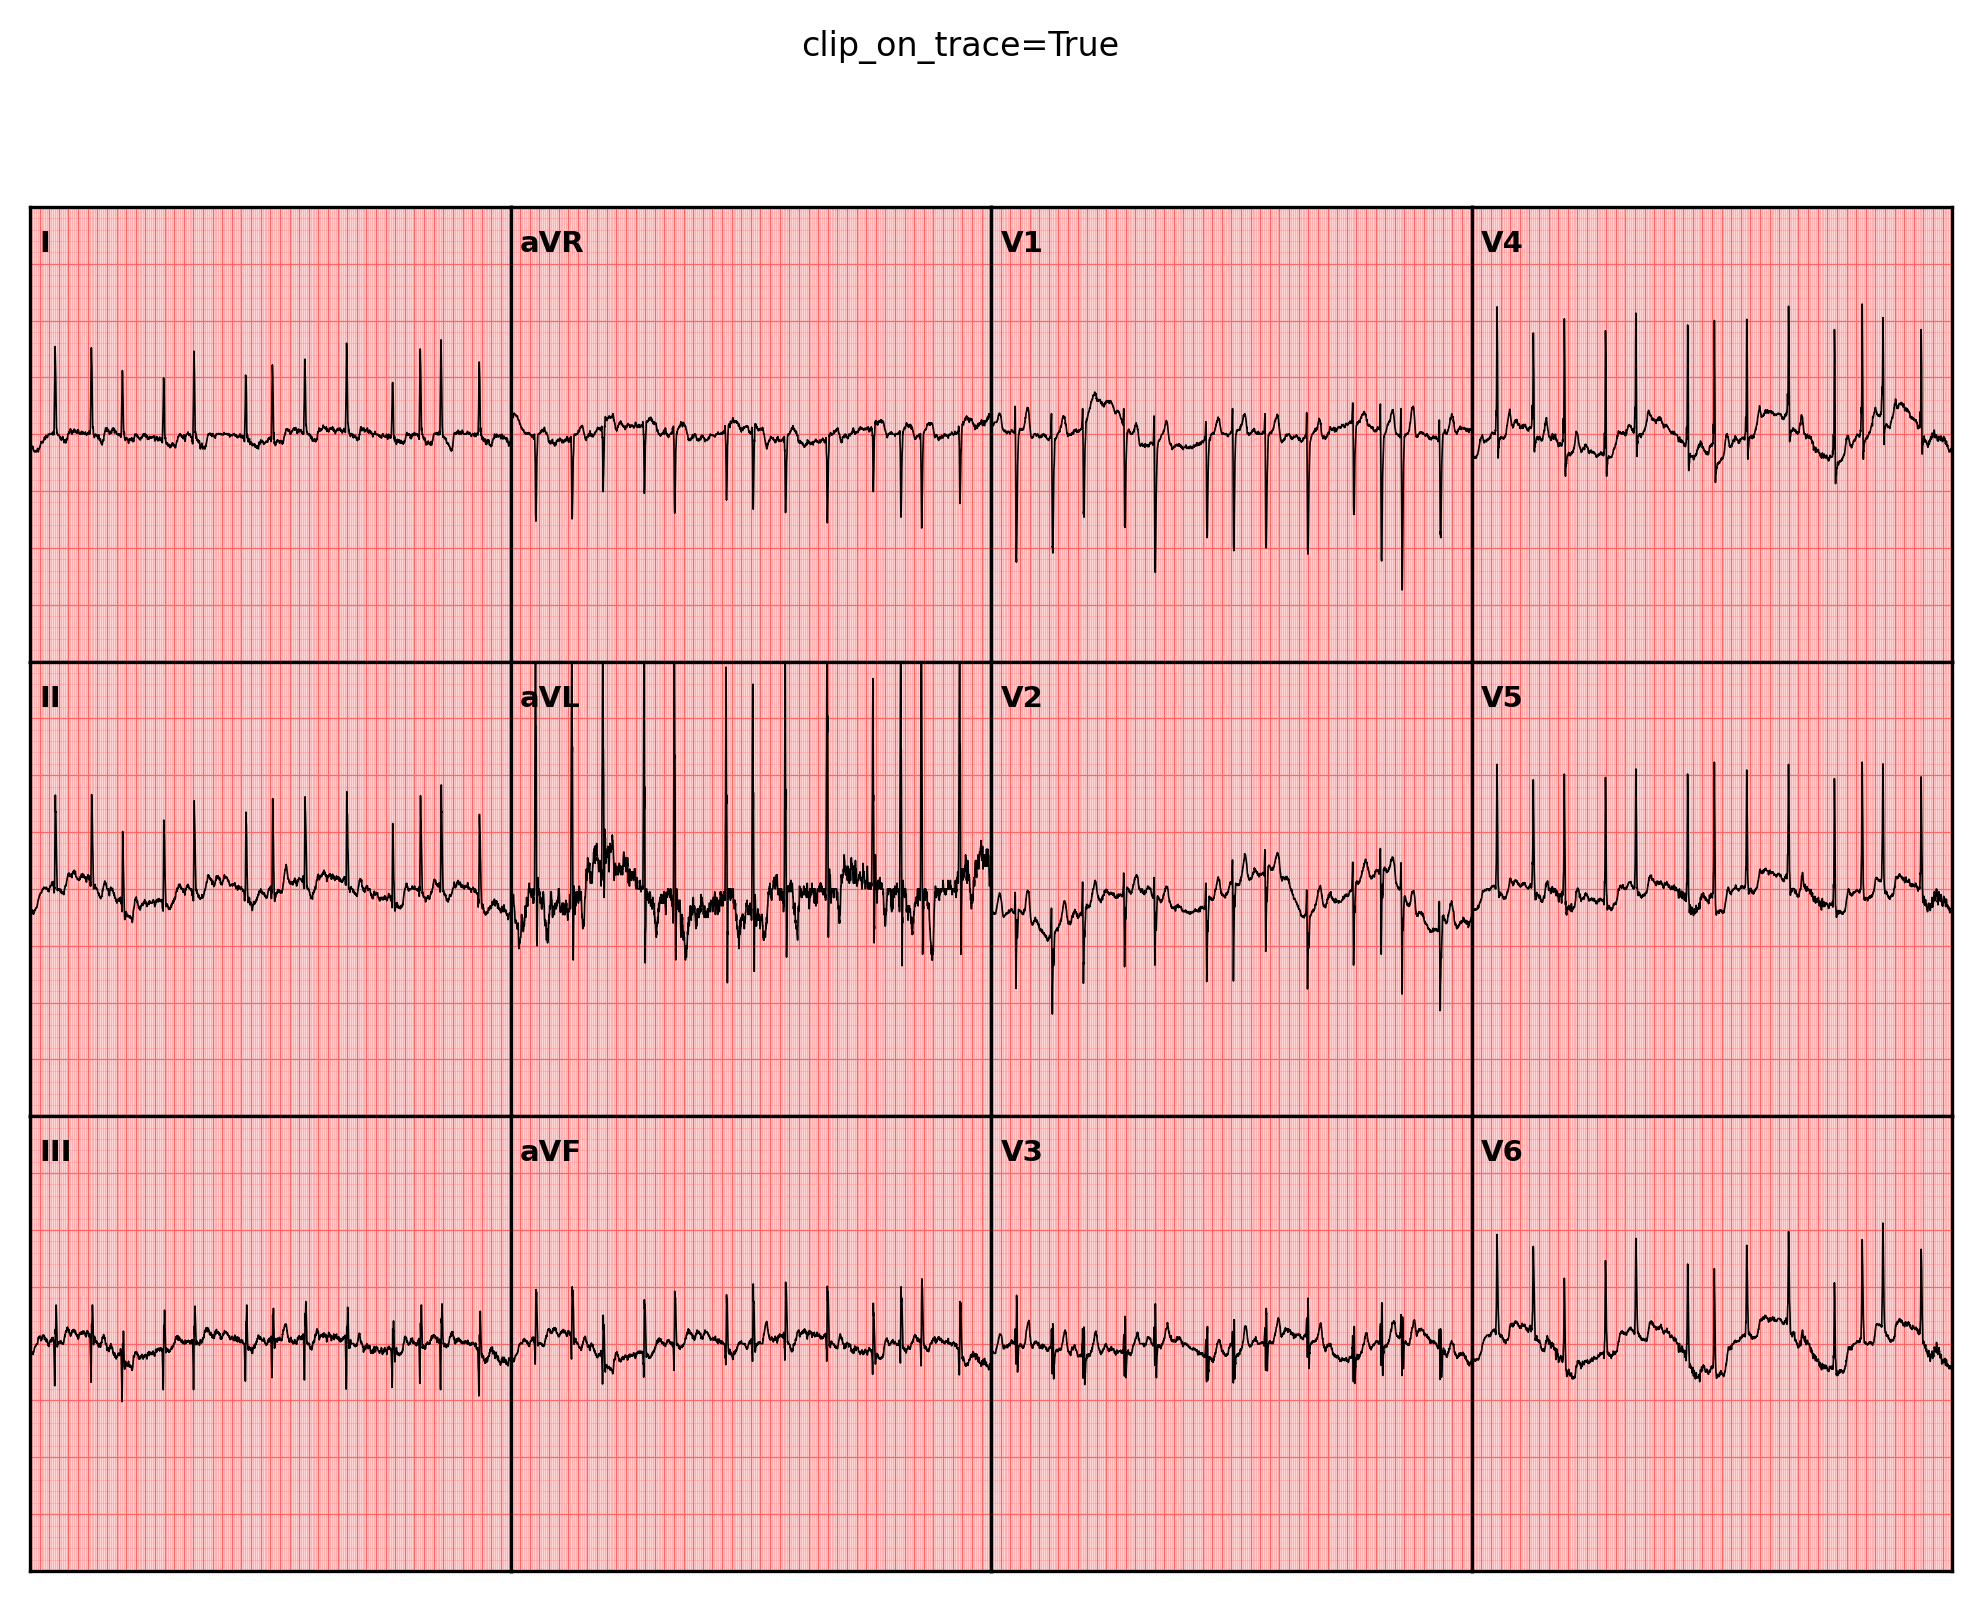

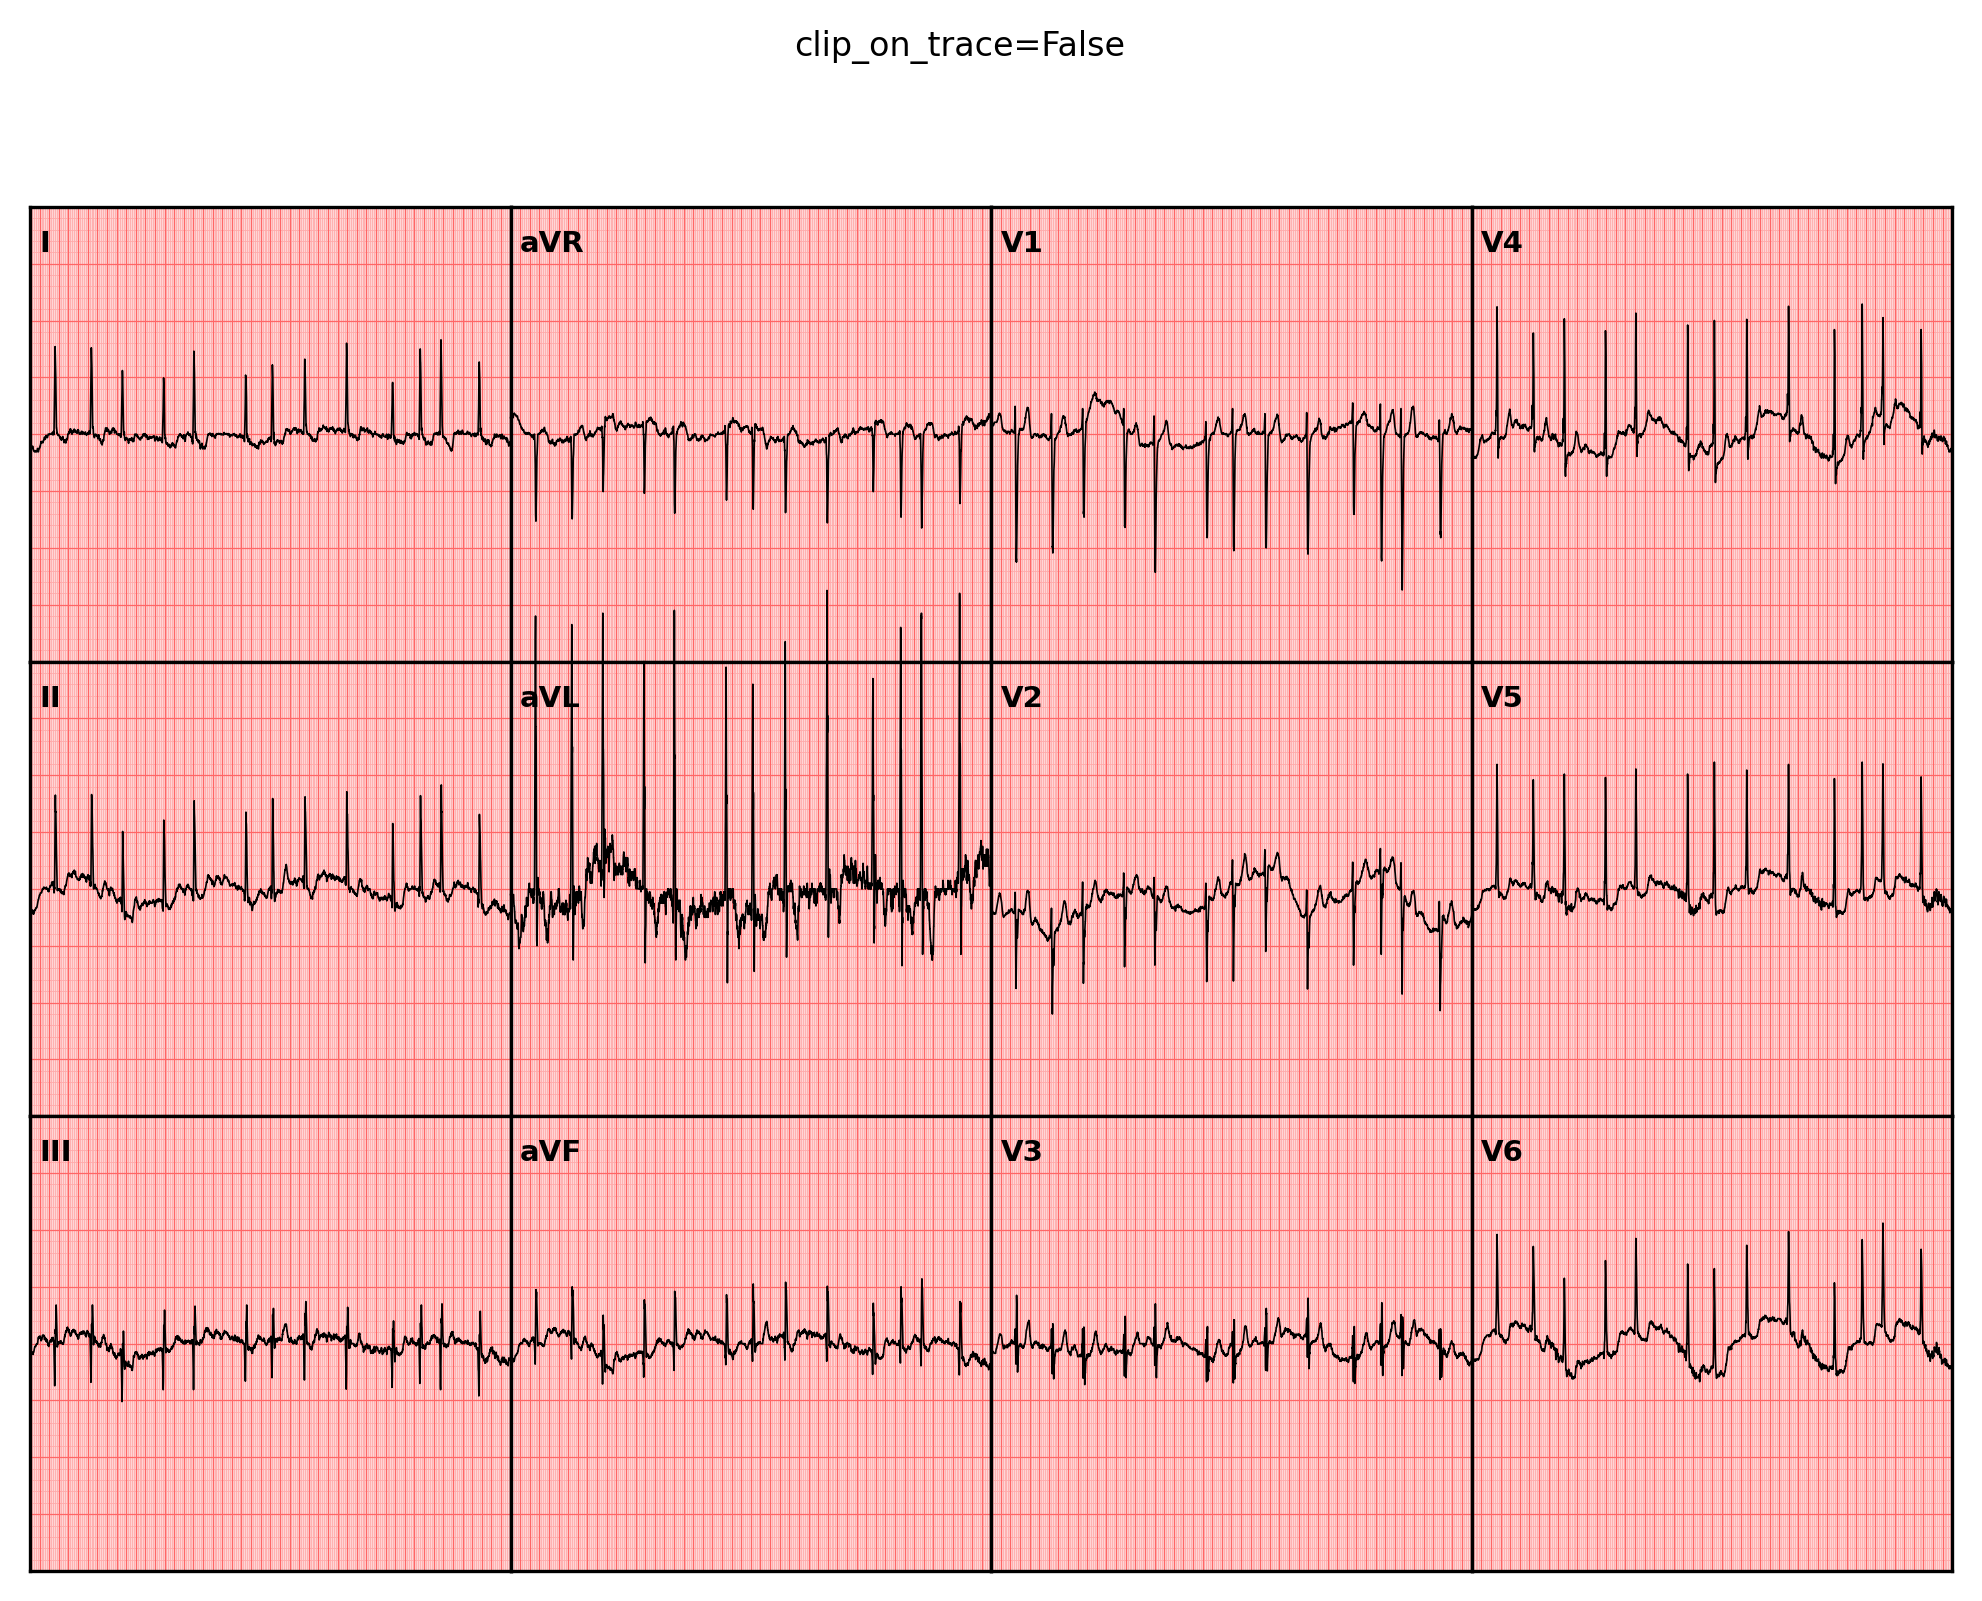

In [11]:
# #### temporarily exaggerate aVL to make clipping visible
_orig_aVL = reader.WaveForms["aVL"]
reader.WaveForms["aVL"] = _orig_aVL * 5

style_on = ECGStyle(
    figsize=(21 * CM_TO_IN, 15 * CM_TO_IN),
    dpi=300,
    y_lim=ylim,
    mm_per_mv=mm_mv,
    clip_on_trace=True,
)
drawing_on = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style_on,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
)
drawing_on.figure.suptitle("clip_on_trace=True", fontsize=8)
plt.show()

style_off = ECGStyle(
    figsize=(21 * CM_TO_IN, 15 * CM_TO_IN),
    dpi=300,
    y_lim=ylim,
    mm_per_mv=mm_mv,
    clip_on_trace=False,
)
drawing_off = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style_off,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
)
drawing_off.figure.suptitle("clip_on_trace=False", fontsize=8)
plt.show()

# #### restore original amplitude
reader.WaveForms["aVL"] = _orig_aVL

## Research figure: limb-leads subset

`ECGStyle.hspace` and `wspace` control panel separation (default `0.0` mimics
continuous ECG paper). Increasing them and keeping spines visible produces a
style suited to research figures or clinical reports. Here the six limb leads
are arranged in a 2-row × 3-column grid with both axes displayed.

Lead 'V1' is in signal data but not requested in mapper.
Lead 'V2' is in signal data but not requested in mapper.
Lead 'V3' is in signal data but not requested in mapper.
Lead 'V4' is in signal data but not requested in mapper.
Lead 'V5' is in signal data but not requested in mapper.
Lead 'V6' is in signal data but not requested in mapper.


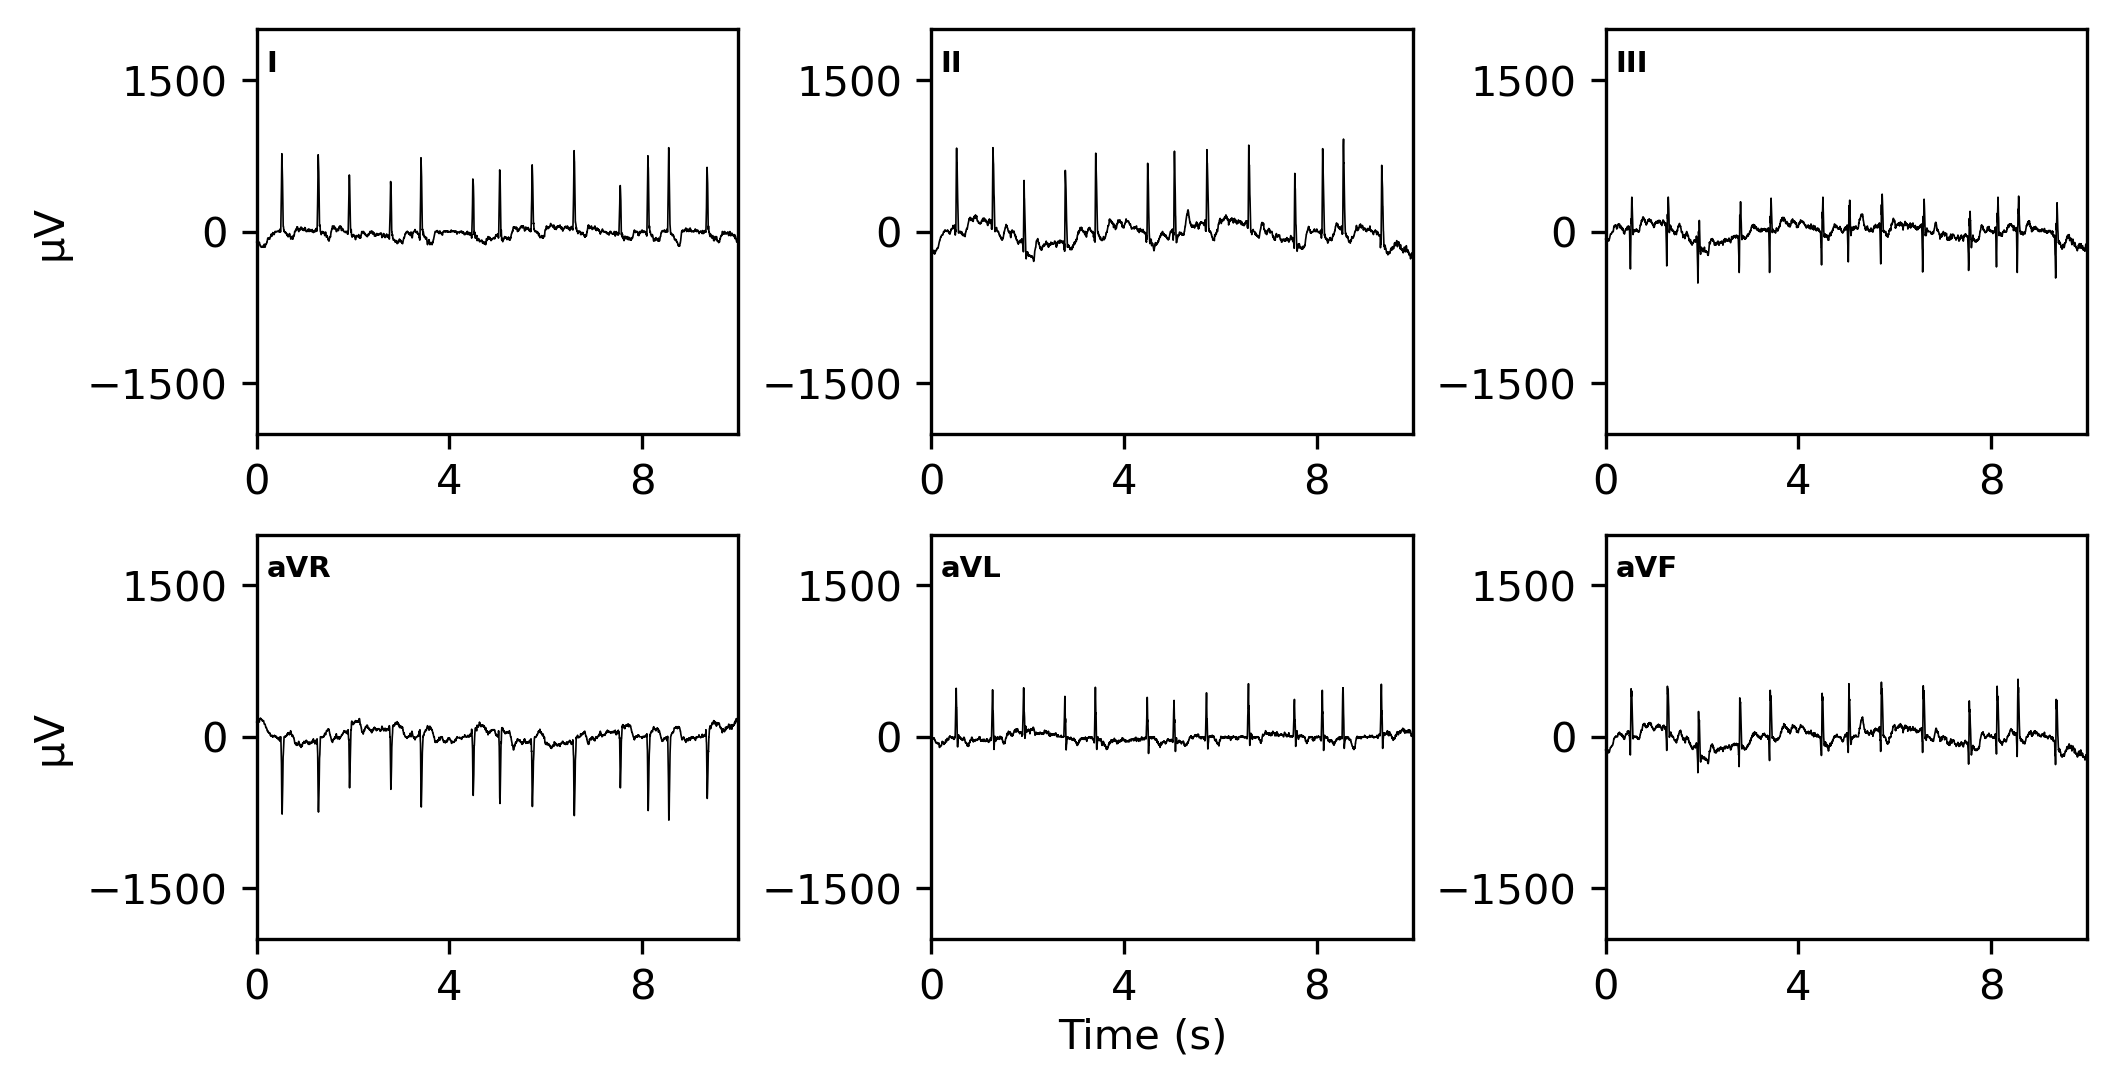

In [12]:
from matplotlib.ticker import MaxNLocator

# #### limb leads, 2×3 grid, separated panels, spines visible
limb_leads = ["I", "II", "III", "aVR", "aVL", "aVF"]
mapper_limb = {
    lead: (row, slice(col, col + 1))
    for i, lead in enumerate(limb_leads)
    for row, col in [divmod(i, 3)]
}
style_research = ECGStyle(
    figsize=(20 * CM_TO_IN, 10 * CM_TO_IN),
    dpi=300,
    hspace=0.25,
    wspace=0.40,
    y_lim=ylim,
    mm_per_mv=mm_mv,
    # turning off the grid
    major_grid_linewidth=0.0,
    minor_grid_linewidth=0.0,
    background_colour="white",
)
drawing_research = ECGDrawing()(
    reader,
    mapper=mapper_limb,
    style=style_research,
    sampling_rate=samplefreq,
    show_axes="b",
    show_lead_labels=True,
)
# #### reduce tick density to prevent label overplotting
for ax in drawing_research.axes.values():
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3, prune="upper"))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, prune="both"))
    ax.set_xlim(left=0)
# #### y-axis label on leftmost panels only
drawing_research.axes["I"].set_ylabel("µV", fontsize=10)
drawing_research.axes["aVR"].set_ylabel("µV", fontsize=10)
# #### single x-axis label below the figure
fig_research = drawing_research.figure
fig_research.supxlabel("Time (s)", fontsize=10, y=0.01)
# Spines intentionally kept — research-figure style
plt.show()

### Plotting from a reader with a custom attribute name (`SOURCE_MAP`)

`ECGDrawing` does not hard-code where signal data live on the reader.
The `SOURCE_MAP` class attribute maps each public ``source`` keyword to
the attribute name looked up via `getattr(reader, ...)`:

```python
ECGDrawing.SOURCE_MAP
# {'waveforms': 'WaveForms', 'median': 'MedianBeats'}
```

This  lets you plot signals from any reader-like object, a third-party reader, a preprocessed wrapper, or a plain
`types.SimpleNamespace`,  as long as the named attribute holds a `dict[str, np.ndarray]` of lead signals.

The example below builds a minimal stand-in reader whose waveform data lives on `reader.Traces` (instead of `WaveForms`), registers a new
``source='traces'`` entry on a single `ECGDrawing` instance, and reuses the canonical 12-lead `mapper` and `style` to render it.

subclass SOURCE_MAP: {'waveforms': 'WaveForms', 'median': 'MedianBeats', 'traces': 'Traces'}


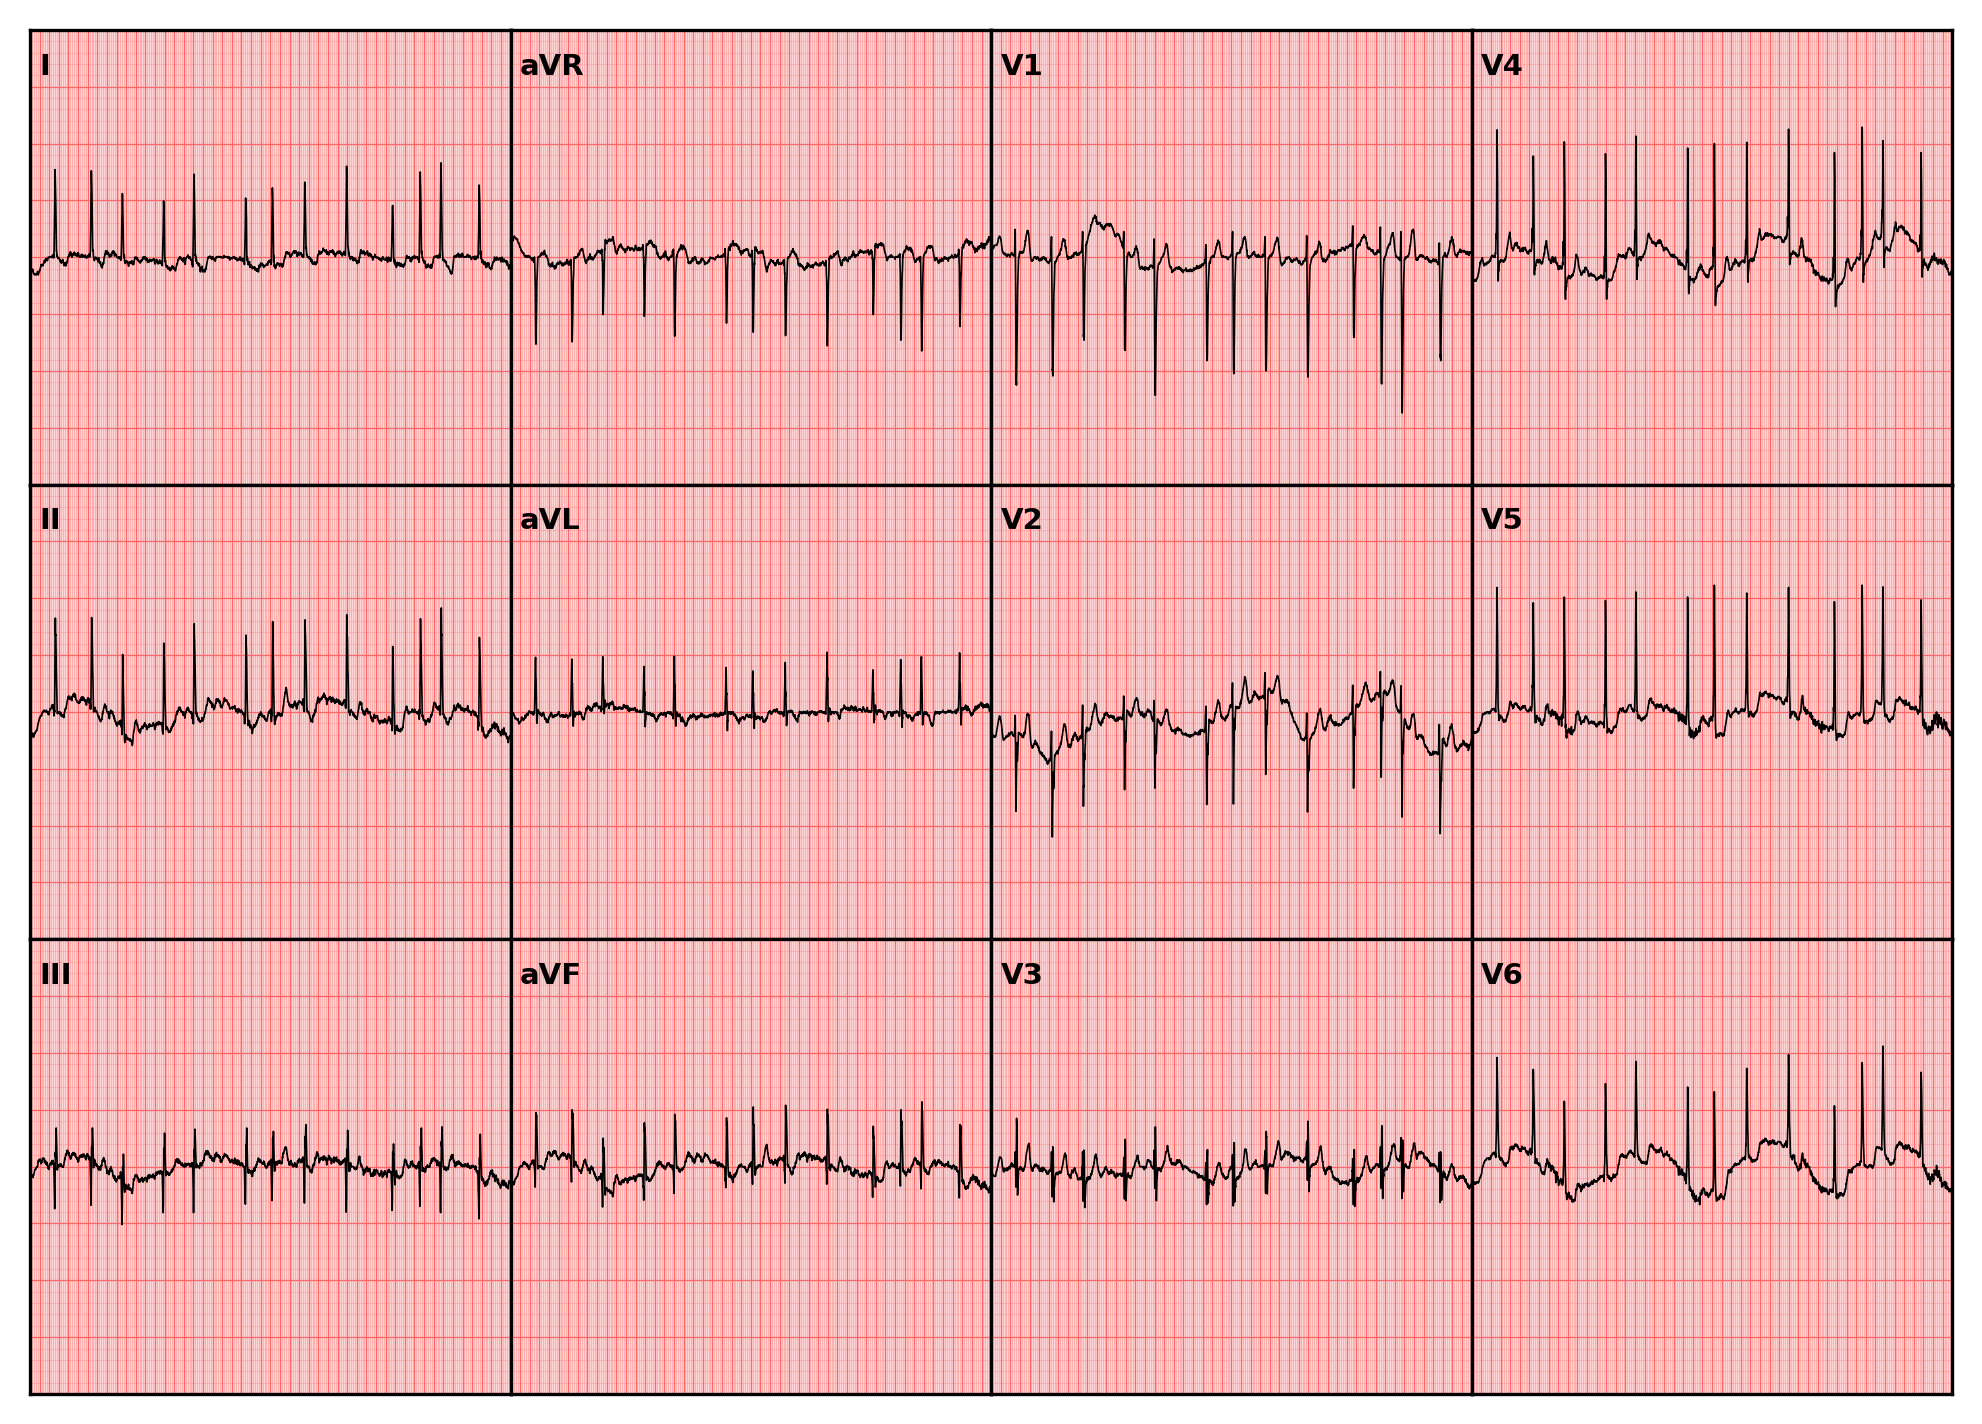

In [13]:
from types import SimpleNamespace

# #### custom reader: signals on `Traces`, not `WaveForms`
# In real code this would be a third-party reader class. Here a plain
# SimpleNamespace shows the only requirement: an attribute whose value is
# a {lead_name: np.ndarray} dict.
custom_reader = SimpleNamespace(
    Traces=dict(reader.WaveForms),
    MetaData=reader.MetaData,
)


# #### subclass to override SOURCE_MAP
# ECGDrawing uses __slots__, so SOURCE_MAP must be overridden at the class
# level rather than assigned on an instance. Subclass and add the new
# source key alongside the defaults.
class CustomECGDrawing(ECGDrawing):
    SOURCE_MAP = {
        **ECGDrawing.SOURCE_MAP,
        "traces": "Traces",
    }


print("subclass SOURCE_MAP:", CustomECGDrawing.SOURCE_MAP)

# #### render using the new source key
drawing_custom = CustomECGDrawing()(
    custom_reader,
    mapper=mapper,
    source="traces",
    style=style,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    cal_pulse=None,
)
plt.show()

## Map figure to numpy array

`to_numpy()` renders an `ECGDrawing` figure to a `(height, width, 4)` uint8
RGBA array. This is useful for embedding ECG images in composite figures or
passing them directly to machine-learning pipelines. Pass `close=False` to
keep the underlying matplotlib figure open for further inspection.

In [14]:
# #### render two drawings to numpy arrays
# canonical 12-lead
arr_clinical = drawing.to_numpy(close=False)
# limb-leads subset
arr_research = drawing_research.to_numpy(close=False)
print(f"clinical  shape={arr_clinical.shape}  dtype={arr_clinical.dtype}")
print(f"research  shape={arr_research.shape}  dtype={arr_research.dtype}")

clinical  shape=(1771, 2480, 4)  dtype=uint8
research  shape=(1181, 2362, 4)  dtype=uint8


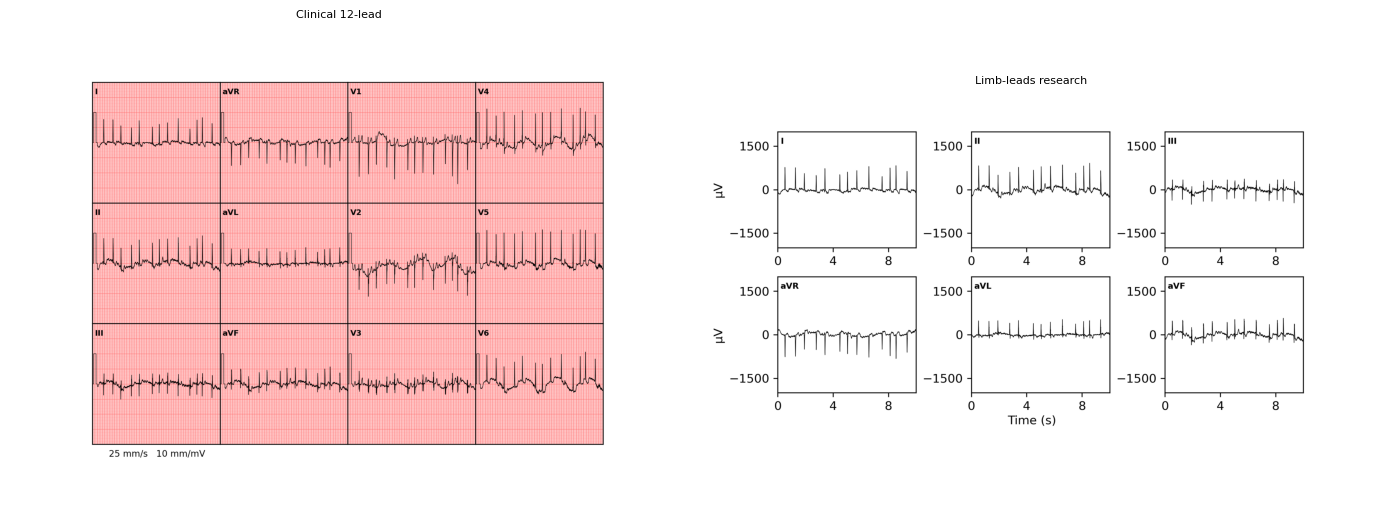

In [15]:
# #### embed ECG images in a composite matplotlib figure
fig_comp, axes_comp = plt.subplots(1, 2, figsize=(14, 5))
axes_comp[0].imshow(arr_clinical)
axes_comp[0].set_title("Clinical 12-lead", fontsize=8)
axes_comp[0].axis("off")
axes_comp[1].imshow(arr_research)
axes_comp[1].set_title("Limb-leads research", fontsize=8)
axes_comp[1].axis("off")
fig_comp.tight_layout()
plt.show()

### Utility for machine learning

`to_numpy()` converts any ECG figure to a `(H, W, 4)` uint8 RGBA array.
Slicing to RGB (`arr[..., :3]`) or converting to grayscale yields a direct
input tensor for standard convolutional classifiers — for example arrhythmia
detection or rhythm classification models. The approach treats the rendered ECG
image as the input representation, which is useful when pre-trained image models
are available and raw-signal models are not. Be aware that DPI, figsize, and
rendering parameters all become implicit hyperparameters of the pipeline.